# US Dollar Index — Exploratory Data Analysis

**Dataset:** `dollar_index.csv`  
**Nguồn:** Yahoo Finance, ticker DX-Y.NYB  
**Vai trò trong dự án:** Nguồn external market cho bài toán Gold phiên kế tiếp.

## Mục tiêu phân tích

1. Hiểu cấu trúc, chất lượng, phân phối và phạm vi thời gian của nguồn dữ liệu.
2. Từ câu hỏi đặc thù của dataset, xây dựng các feature ứng viên và mô tả chúng.
3. Ghi nhận bằng chứng cần có trước khi quyết định giữ feature cho bài toán Gold phiên kế tiếp.

## Cấu trúc notebook

- **Part 1 — Data Profiling:** chỉ phân tích biến gốc.
- **Part 2 — Feature-oriented EDA:** câu hỏi → đại lượng cần đo → feature → EDA.


**Phạm vi:** snapshot EDA 2010–2026 của bốn nguồn Yahoo Finance; dữ liệu modeling 2005–2026 được xử lý riêng.

## Part 1 — Data Profiling

Phần này trả lời: dữ liệu có gì, có sạch không, phân phối cơ bản ra sao và trải dài trong thời gian nào? Chưa tạo return, MA, RSI hoặc MACD.


### 1.1 Thư viện và nguồn dữ liệu

In [1]:
from pathlib import Path



In [2]:

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/modeling/horizons').is_dir() and (p/'notebook').is_dir())
DATA_DIR = ROOT / 'data/eda_2010_2026'
FILE_NAME = 'dollar_index.csv'
DATA_PATH = DATA_DIR / FILE_NAME
RAW_NUMERIC = ['Open', 'High', 'Low', 'Close', 'Volume']
TITLE = 'US Dollar Index'


pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

### 1.2 Đọc dữ liệu và chuẩn hóa định dạng

Chuẩn hóa tên Date, parse ngày và numeric trên bản sao. Đếm lỗi chuyển đổi; không impute và không xóa quan sát. Hai dòng metadata Yahoo không phải quan sát thị trường.


In [3]:

metadata = pd.read_csv(DATA_PATH, nrows=2)
print('\nThông tin metadata của file nguồn')
display(metadata)

if metadata.iloc[0, 0] == 'Ticker' and metadata.iloc[1, 0] == 'Date':
    print('Metadata đúng định dạng Ticker/Date.')
else:
    print('Cảnh báo: Metadata không đúng định dạng Ticker/Date dự kiến; cần kiểm tra cách đọc file.')

if (metadata.iloc[0, 1:] == 'DX-Y.NYB').all():
    print('Ticker đúng nguồn dự kiến.')
else:
    print('Cảnh báo: Ticker không đúng nguồn dự kiến.')

raw = pd.read_csv(DATA_PATH, skiprows=[1, 2])

if set(raw.columns) == {'Price', 'Open', 'High', 'Low', 'Close', 'Volume'}:
    print('Các cột đúng schema dự kiến.')
else:
    print('Cảnh báo: Các cột trong file khác schema dự kiến; xem tên cột trước khi phân tích tiếp.')

df = raw.rename(columns={'Price': 'Date'}).copy()


original_dates = df['Date'].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
parse_failures = {'Date': int((original_dates.notna() & df['Date'].isna()).sum())}

for column in RAW_NUMERIC:
    original_values = df[column].copy()
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

input_sorted = df['Date'].is_monotonic_increasing
df = df.sort_values('Date', kind='stable').reset_index(drop=True)
print('\n5 dòng đầu của dữ liệu')
display(df.head())
print('\n5 dòng cuối của dữ liệu')
display(df.tail())


Thông tin metadata của file nguồn


,Price,Close,High,Low,Open,Volume
0,Ticker,DX-Y.NYB,DX-Y.NYB,DX-Y.NYB,DX-Y.NYB,DX-Y.NYB
1,Date,NaN,NaN,NaN,NaN,NaN


Metadata đúng định dạng Ticker/Date.
Ticker đúng nguồn dự kiến.
Các cột đúng schema dự kiến.

5 dòng đầu của dữ liệu


,Date,Close,High,Low,Open,Volume
0,2010-01-04,77.529999,78.190002,77.260002,77.930000,0
1,2010-01-05,77.620003,77.709999,77.089996,77.370003,0
2,2010-01-06,77.489998,78.000000,77.360001,77.650002,0
3,2010-01-07,77.910004,78.080002,77.300003,77.370003,0
4,2010-01-08,77.470001,78.190002,77.349998,77.980003,0



5 dòng cuối của dữ liệu


,Date,Close,High,Low,Open,Volume
4199,2026-09-14,99.459999,99.739998,99.070000,99.099998,0
4200,2026-09-15,99.650002,99.690002,99.480003,99.480003,0
4201,2026-09-16,100.309998,100.349998,99.540001,99.699997,0
4202,2026-09-17,100.220001,100.370003,100.019997,100.269997,0
4203,2026-09-18,100.220001,100.559998,100.169998,100.239998,0


### 1.3 Kích thước và phạm vi thời gian

“Số ngày quan sát” là số Date hợp lệ khác nhau; khác với số ngày lịch giữa đầu và cuối chuỗi.


In [4]:

overview = pd.DataFrame([{
    'Rows': len(df), 'Columns_including_Date': len(df.columns),
    'Start_date': df['Date'].min(), 'End_date': df['Date'].max(),
    'Unique_observed_dates': df['Date'].nunique(),
    'Calendar_span_days': (df['Date'].max() - df['Date'].min()).days + 1,
    'Rows_removed': len(raw) - len(df), 'Originally_sorted': input_sorted
}])
print('\nTổng quan kích thước và phạm vi thời gian')
display(overview)
print('\nSố dòng quan sát theo năm')
display(df.groupby(df['Date'].dt.year).size().rename('Observed_rows').to_frame())


Tổng quan kích thước và phạm vi thời gian


,Rows,Columns_including_Date,Start_date,End_date,Unique_observed_dates,Calendar_span_days,Rows_removed,Originally_sorted
0,4204,6,2010-01-04,2026-09-18,4204,6102,0,True



Số dòng quan sát theo năm


,Observed_rows
Date,
2010,252
2011,252
2012,250
2013,252
2014,252
2015,252
2016,251
2017,251
2018,251


### 1.4 Data schema và ý nghĩa biến

Phân biệt đơn vị giá/chỉ số với khối lượng. Những mô tả nguồn chưa xác minh được ghi rõ.


In [5]:

column_meaning = {'Date': 'Nhãn ngày quan sát của nguồn, chưa xác minh giờ chốt', 'Open': 'Giá/mức chỉ số mở cửa do nguồn cung cấp', 'High': 'Giá/mức chỉ số cao nhất theo nguồn', 'Low': 'Giá/mức chỉ số thấp nhất theo nguồn', 'Close': 'Giá/mức chỉ số Close; cần xác minh close/settlement với futures', 'Volume': 'Khối lượng do nguồn cung cấp; không so sánh trực tiếp giữa các thị trường'}

column_units = {'Open': 'Index points', 'High': 'Index points', 'Low': 'Index points', 'Close': 'Index points', 'Volume': 'Source-reported volume; cần xác minh đơn vị', 'Date': 'YYYY-MM-DD'}

schema = pd.DataFrame({
    'Column': df.columns,
    'Dtype': [str(df[c].dtype) for c in df.columns],
    'Meaning': [column_meaning[c] for c in df.columns],
    'Unit': [column_units[c] for c in df.columns]
})
print('\nCấu trúc dữ liệu và ý nghĩa từng cột')
display(schema)


Cấu trúc dữ liệu và ý nghĩa từng cột


,Column,Dtype,Meaning,Unit
0,Date,datetime64[us],"Nhãn ngày quan sát của nguồn, chưa xác minh gi...",YYYY-MM-DD
1,Close,float64,Giá/mức chỉ số Close; cần xác minh close/settl...,Index points
2,High,float64,Giá/mức chỉ số cao nhất theo nguồn,Index points
3,Low,float64,Giá/mức chỉ số thấp nhất theo nguồn,Index points
4,Open,float64,Giá/mức chỉ số mở cửa do nguồn cung cấp,Index points
5,Volume,int64,Khối lượng do nguồn cung cấp; không so sánh tr...,Source-reported volume; cần xác minh đơn vị


### 1.5 Missing values, duplicates và độ phủ ngày

**Câu hỏi:** có thiếu giá trị trong các dòng đã có, có ngày trùng, hoặc có ngày cần đối chiếu lịch nguồn không?

Phân biệt **missing cell** với **ngày không có bản ghi**. Daily data không nhất thiết có bản ghi cho mọi ngày lịch. Cuối tuần được tách riêng; ngày thứ Hai–thứ Sáu vắng mặt vẫn có thể là ngày nghỉ hoặc khác biệt lịch phiên, chưa gọi là lỗi crawl.

**Thống kê và biểu đồ:** số lượng ngắn gọn, biểu đồ ngày vắng theo năm và vị trí các ngày thường vắng. Bảng chi tiết chỉ hiện tối đa 20 dòng để xem mẫu. Không fill thêm ngày hoặc giá.



Thống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu


,Missing_cells,Missing_percent,Parse_failures
Close,0,0.0,0
Date,0,0.0,0
High,0,0.0,0
Low,0,0.0,0
Open,0,0.0,0
Volume,0,0.0,0


Duplicate raw rows: 0
Duplicate normalized rows: 0
Không có ngày bị trùng.

Các dòng có ngày bị trùng


,Date,Close,High,Low,Open,Volume



Tổng số ngày lịch không có bản ghi: 1,898
Trong đó, ngày cuối tuần: 1,742
Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: 156
Các số này chưa phải số phiên bị mất dữ liệu.

Biểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm


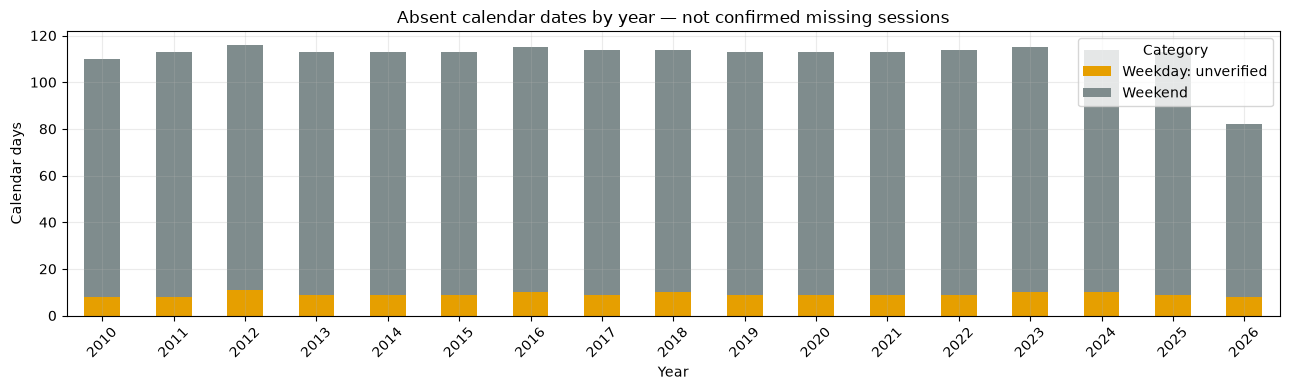


Vị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không


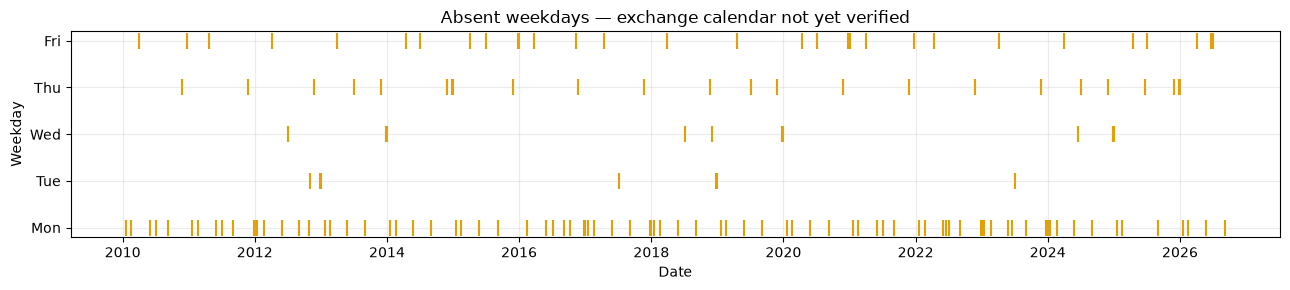


Tối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)


,Absent_date
4,2010-01-18
13,2010-02-15
26,2010-04-02
45,2010-05-31
56,2010-07-05
75,2010-09-06
98,2010-11-25
107,2010-12-24
116,2011-01-17
127,2011-02-21



10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ


,Date,Previous_date,Gap_calendar_days,Absent_dates_between
712,2012-10-31,2012-10-26,5.0,4.0
10,2010-01-19,2010-01-15,4.0,3.0
29,2010-02-16,2010-02-12,4.0,3.0
62,2010-04-05,2010-04-01,4.0,3.0
102,2010-06-01,2010-05-28,4.0,3.0
126,2010-07-06,2010-07-02,4.0,3.0
170,2010-09-07,2010-09-03,4.0,3.0
247,2010-12-27,2010-12-23,4.0,3.0
262,2011-01-18,2011-01-14,4.0,3.0
286,2011-02-22,2011-02-18,4.0,3.0


In [6]:


quality = pd.DataFrame({
    'Missing_cells': df.isna().sum(),
    'Missing_percent': df.isna().mean() * 100,
    'Parse_failures': pd.Series(parse_failures)
})
print('\nThống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu')
display(quality)
print('Duplicate raw rows:', int(raw.duplicated().sum()))
print('Duplicate normalized rows:', int(df.duplicated().sum()))

duplicate_dates = df.loc[df['Date'].notna(), 'Date'].duplicated().sum()
if duplicate_dates > 0:
    print(f'Cảnh báo: Có {duplicate_dates} ngày bị trùng.')
else:
    print('Không có ngày bị trùng.')
print('\nCác dòng có ngày bị trùng')
display(df.loc[df['Date'].notna() & df['Date'].duplicated(keep=False)])


observed_dates = pd.DatetimeIndex(df['Date'].dropna().unique()).sort_values()
if len(observed_dates) == 0:
    print('Không có ngày hợp lệ để kiểm tra độ phủ.')
else:
    calendar = pd.date_range(observed_dates.min(), observed_dates.max(), freq='D')
    absent_dates = calendar.difference(observed_dates)
    gap_table = pd.DataFrame({'Absent_date': absent_dates})
    gap_table['Weekend'] = gap_table['Absent_date'].dt.dayofweek >= 5
    weekday_gaps = gap_table.loc[~gap_table['Weekend']].copy()
    print(f'\nTổng số ngày lịch không có bản ghi: {len(gap_table):,}')
    print(f'Trong đó, ngày cuối tuần: {int(gap_table["Weekend"].sum()):,}')
    print(f'Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: {len(weekday_gaps):,}')
    print('Các số này chưa phải số phiên bị mất dữ liệu.')

    
    gap_table['Year'] = gap_table['Absent_date'].dt.year
    gap_table['Category'] = gap_table['Weekend'].map({True: 'Weekend', False: 'Weekday: unverified'})
    yearly_gaps = pd.crosstab(gap_table['Year'], gap_table['Category'])
    if not yearly_gaps.empty:
        print('\nBiểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm')
        yearly_gaps.plot.bar(stacked=True, figsize=(13, 4), color=['#e69f00', '#7f8c8d'])
        plt.title('Absent calendar dates by year — not confirmed missing sessions')
        plt.xlabel('Year')
        plt.ylabel('Calendar days')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    if weekday_gaps.empty:
        print('Không có ngày thứ Hai–thứ Sáu vắng trong phạm vi dữ liệu.')
    else:
        print('\nVị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không')
        fig, ax = plt.subplots(figsize=(13, 3))
        ax.scatter(weekday_gaps['Absent_date'], weekday_gaps['Absent_date'].dt.dayofweek,
                   color='#e69f00', marker='|', s=130)
        ax.set_yticks([0, 1, 2, 3, 4], ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])
        ax.set(title='Absent weekdays — exchange calendar not yet verified', xlabel='Date', ylabel='Weekday')
        plt.tight_layout()
        plt.show()
        print('\nTối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)')
        display(weekday_gaps[['Absent_date']].head(20))

    
    consecutive_gaps = pd.Series(observed_dates).to_frame('Date')
    consecutive_gaps['Previous_date'] = consecutive_gaps['Date'].shift(1)
    consecutive_gaps['Gap_calendar_days'] = consecutive_gaps['Date'].diff().dt.days
    consecutive_gaps['Absent_dates_between'] = consecutive_gaps['Gap_calendar_days'] - 1
    long_gaps = consecutive_gaps.loc[consecutive_gaps['Gap_calendar_days'] > 1]
    if not long_gaps.empty:
        print('\n10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ')
        display(long_gaps.nlargest(10, 'Gap_calendar_days'))

### 1.6 Giá trị bất thường và tính hợp lệ

**Mục tiêu:** phân biệt cờ kiểm tra domain với điểm ngoài phân phối chung. Cả hai đều chưa chứng minh bản ghi sai.

IQR = Q3 − Q1. Điểm ngoài [Q1 − 1.5×IQR, Q3 + 1.5×IQR] được tô cam trên chuỗi thời gian, kèm hai hàng rào nét đứt và số điểm bị flag. Một cụm cam kéo dài có thể phản ánh thay đổi mặt bằng; điểm cam riêng lẻ cần xem các ngày lân cận. IQR toàn kỳ không xét thứ tự thời gian, không dùng làm quy tắc tự xóa hoặc ngưỡng modeling.

**Thống kê và biểu đồ:** bảng cờ kiểm tra có tiêu đề và biểu đồ thời gian cho từng biến gốc. Nếu IQR=0 do dữ liệu lặp nhiều, đọc cảnh báo và không coi mọi điểm khác mức phổ biến là lỗi.

**Dữ liệu thị trường:** cần đối chiếu ý nghĩa OHLC/Close, Volume và nguồn trước khi sửa. Uy tín nguồn không thay thế kiểm tra chất lượng.



Số dòng được gắn cờ theo từng kiểm tra chất lượng


,Flagged_rows
Invalid_date,0
Nonfinite_or_missing_numeric,0
High_below_Low,0
Open_outside_range,0
Close_outside_range,0
Nonpositive_price_review,0
Negative_volume,0
Zero_volume_review,4202



Chi tiết các dòng được gắn cờ cần xem xét


,Date,Close,High,Low,Open,Volume,Invalid_date,Nonfinite_or_missing_numeric,High_below_Low,Open_outside_range,Close_outside_range,Nonpositive_price_review,Negative_volume,Zero_volume_review
0,2010-01-04,77.529999,78.190002,77.260002,77.930000,0,False,False,False,False,False,False,False,True
1,2010-01-05,77.620003,77.709999,77.089996,77.370003,0,False,False,False,False,False,False,False,True
2,2010-01-06,77.489998,78.000000,77.360001,77.650002,0,False,False,False,False,False,False,False,True
3,2010-01-07,77.910004,78.080002,77.300003,77.370003,0,False,False,False,False,False,False,False,True
4,2010-01-08,77.470001,78.190002,77.349998,77.980003,0,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4199,2026-09-14,99.459999,99.739998,99.070000,99.099998,0,False,False,False,False,False,False,False,True
4200,2026-09-15,99.650002,99.690002,99.480003,99.480003,0,False,False,False,False,False,False,False,True
4201,2026-09-16,100.309998,100.349998,99.540001,99.699997,0,False,False,False,False,False,False,False,True
4202,2026-09-17,100.220001,100.370003,100.019997,100.269997,0,False,False,False,False,False,False,False,True



Open — điểm ngoài hàng rào IQR theo thời gian
0/4,204 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: 57.85; hàng rào trên: 124.33.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


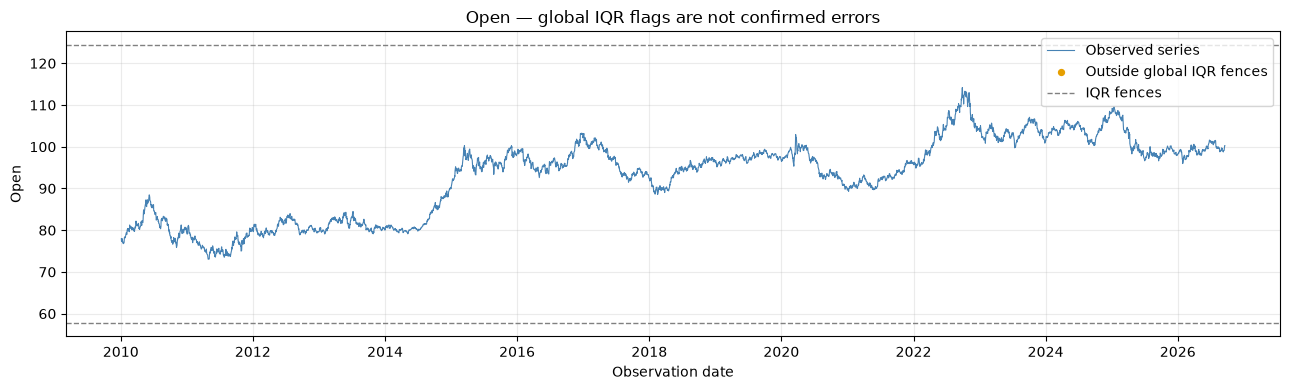


High — điểm ngoài hàng rào IQR theo thời gian
0/4,204 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: 58.18; hàng rào trên: 124.62.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


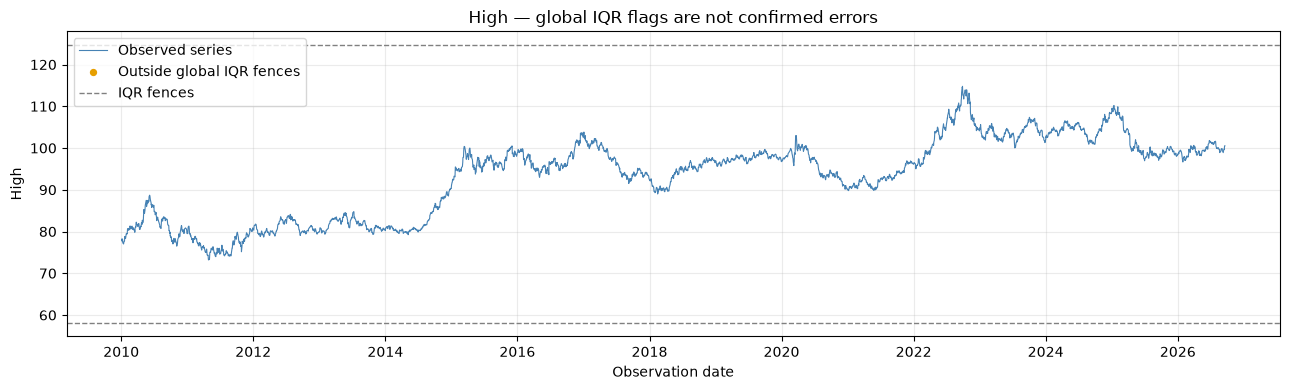


Low — điểm ngoài hàng rào IQR theo thời gian
0/4,204 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: 57.50; hàng rào trên: 124.01.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


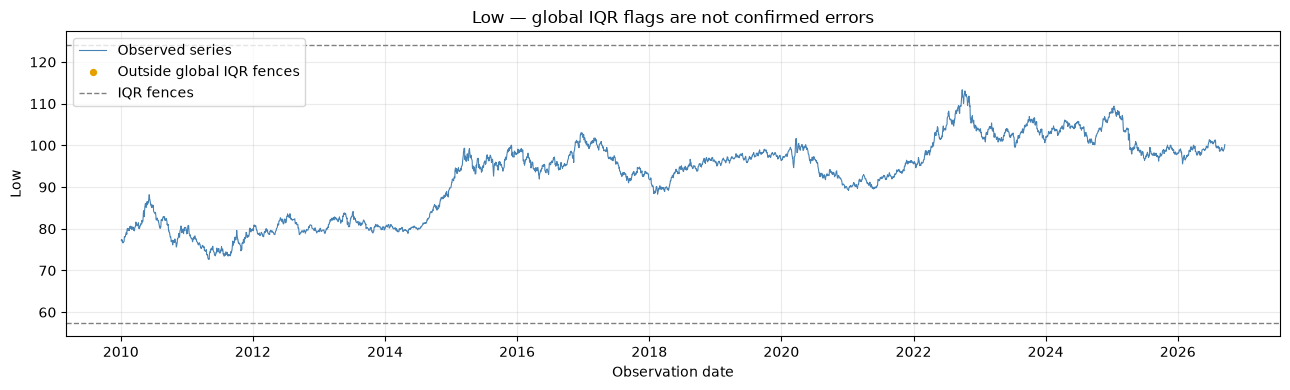


Close — điểm ngoài hàng rào IQR theo thời gian
0/4,204 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: 57.88; hàng rào trên: 124.33.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


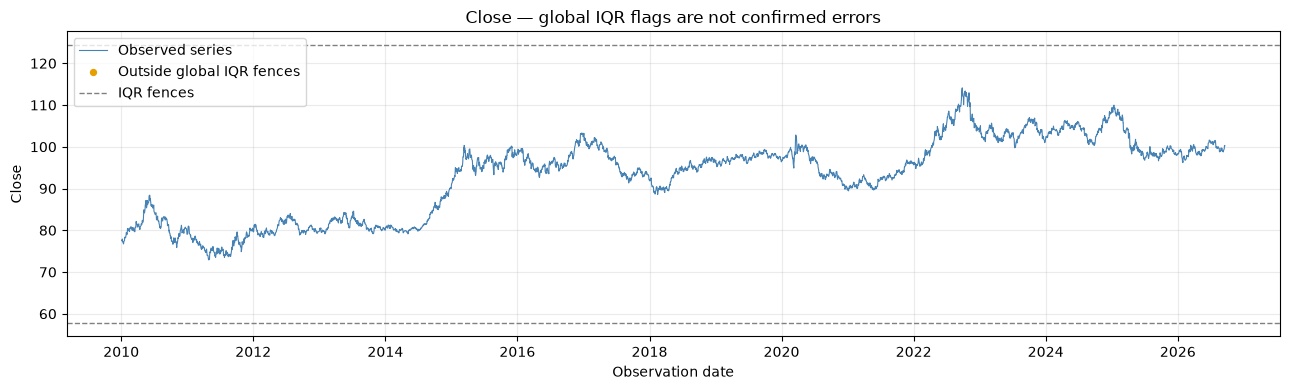


Volume — điểm ngoài hàng rào IQR theo thời gian
2/4,204 điểm hữu hạn bị flag (0.05%).
Hàng rào dưới: 0.00; hàng rào trên: 0.00.
Lưu ý: IQR = 0, quy tắc này có thể flag nhiều điểm chỉ vì dữ liệu tập trung tại một mức.
Ngày bị flag đầu/cuối: 2015-01-22 đến 2015-01-27.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


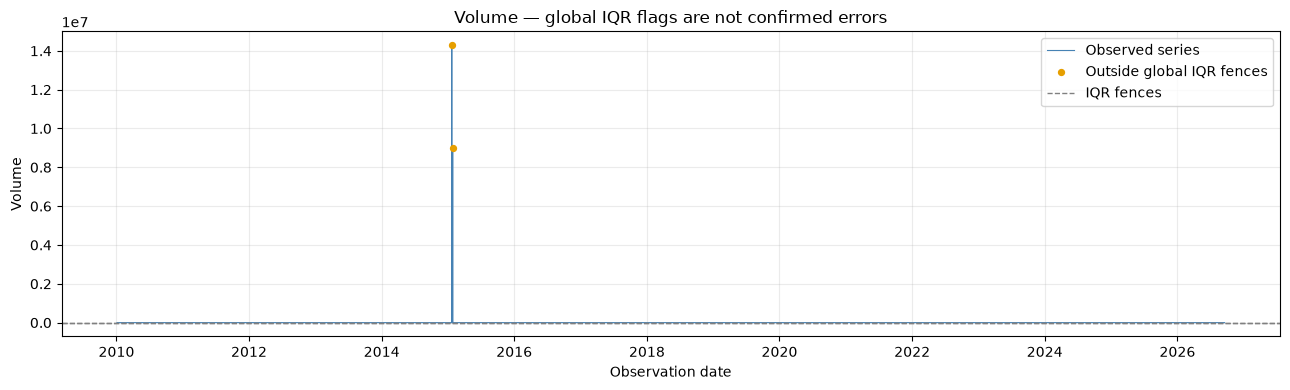

In [7]:

flags = pd.DataFrame(index=df.index)
flags['Invalid_date'] = df['Date'].isna()
flags['Nonfinite_or_missing_numeric'] = df[RAW_NUMERIC].isna().any(axis=1) | df[RAW_NUMERIC].isin([float('inf'), -float('inf')]).any(axis=1)
flags['High_below_Low'] = df['High'] < df['Low']
flags['Open_outside_range'] = (df['Open'] < df['Low']) | (df['Open'] > df['High'])
flags['Close_outside_range'] = (df['Close'] < df['Low']) | (df['Close'] > df['High'])
flags['Nonpositive_price_review'] = (df[['Open','High','Low','Close']] <= 0).any(axis=1)
flags['Negative_volume'] = df['Volume'] < 0
flags['Zero_volume_review'] = df['Volume'] == 0
print('\nSố dòng được gắn cờ theo từng kiểm tra chất lượng')
display(flags.sum().rename('Flagged_rows').to_frame())

flagged_rows = df.loc[flags.any(axis=1)].join(flags.loc[flags.any(axis=1)])
print('\nChi tiết các dòng được gắn cờ cần xem xét')
display(flagged_rows)


iqr_flags = pd.DataFrame(index=df.index)


for column in RAW_NUMERIC:
    values = df[column].replace([float('inf'), -float('inf')], float('nan'))
    valid_values = values.dropna()
    if valid_values.empty:
        print(f'\n{column}: không có giá trị hữu hạn để kiểm tra IQR.')
        continue

    
    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outside_iqr = values.notna() & ((values < lower_fence) | (values > upper_fence))
    iqr_flags[column] = outside_iqr
    flagged_count = int(outside_iqr.sum())
    flagged_percent = 100 * flagged_count / len(valid_values)

    print(f'\n{column} — điểm ngoài hàng rào IQR theo thời gian')
    print(f'{flagged_count:,}/{len(valid_values):,} điểm hữu hạn bị flag ({flagged_percent:.2f}%).')
    print(f'Hàng rào dưới: {lower_fence:,.2f}; hàng rào trên: {upper_fence:,.2f}.')
    if iqr == 0:
        print('Lưu ý: IQR = 0, quy tắc này có thể flag nhiều điểm chỉ vì dữ liệu tập trung tại một mức.')
    if flagged_count > 0:
        flagged_dates = df.loc[outside_iqr, 'Date']
        print(f'Ngày bị flag đầu/cuối: {flagged_dates.min():%Y-%m-%d} đến {flagged_dates.max():%Y-%m-%d}.')
        print('Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.')
    else:
        print('Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.')

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(df['Date'], values, color='steelblue', linewidth=0.8, label='Observed series')
    ax.scatter(df.loc[outside_iqr, 'Date'], values.loc[outside_iqr],
               color='#e69f00', s=18, zorder=3, label='Outside global IQR fences')
    ax.axhline(lower_fence, color='gray', linestyle='--', linewidth=1, label='IQR fences')
    ax.axhline(upper_fence, color='gray', linestyle='--', linewidth=1)
    ax.set_title(column + ' — global IQR flags are not confirmed errors')
    ax.set_xlabel('Observation date')
    ax.set_ylabel(column)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 1.7 Thống kê mô tả các biến gốc

Mean, median, sample standard deviation (ddof=1), min, max và quartiles. NaN/inf không tham gia thống kê hữu hạn; đã được báo riêng ở kiểm tra chất lượng.


In [8]:

raw_finite = df[RAW_NUMERIC].replace([float('inf'), -float('inf')], float('nan'))

descriptive = raw_finite.describe(percentiles=[.25, .5, .75]).T
descriptive = descriptive.rename(columns={'50%': 'median'})
print('\nThống kê mô tả các biến gốc')
display(descriptive[['count','mean','median','std','min','25%','75%','max']])


Thống kê mô tả các biến gốc


,count,mean,median,std,min,25%,75%,max
Open,4204.0,92.995645,95.570000,9.270647,73.059998,82.782501,99.402502,1.141900e+02
High,4204.0,93.314360,95.860001,9.278299,73.199997,83.099998,99.709999,1.147800e+02
Low,4204.0,92.699365,95.239998,9.246447,72.699997,82.440002,99.070000,1.133300e+02
Close,4204.0,93.011068,95.564999,9.266586,72.930000,82.797503,99.410004,1.141100e+02
Volume,4204.0,5539.961941,0.000000,260435.347327,0.000000,0.000000,0.000000,1.429000e+07


### 1.8 Phân phối các biến gốc

Mỗi biến có histogram và boxplot riêng. Giữ toàn bộ giá trị hữu hạn, không cắt đuôi hoặc winsorize. Đây chưa phải phân phối return.


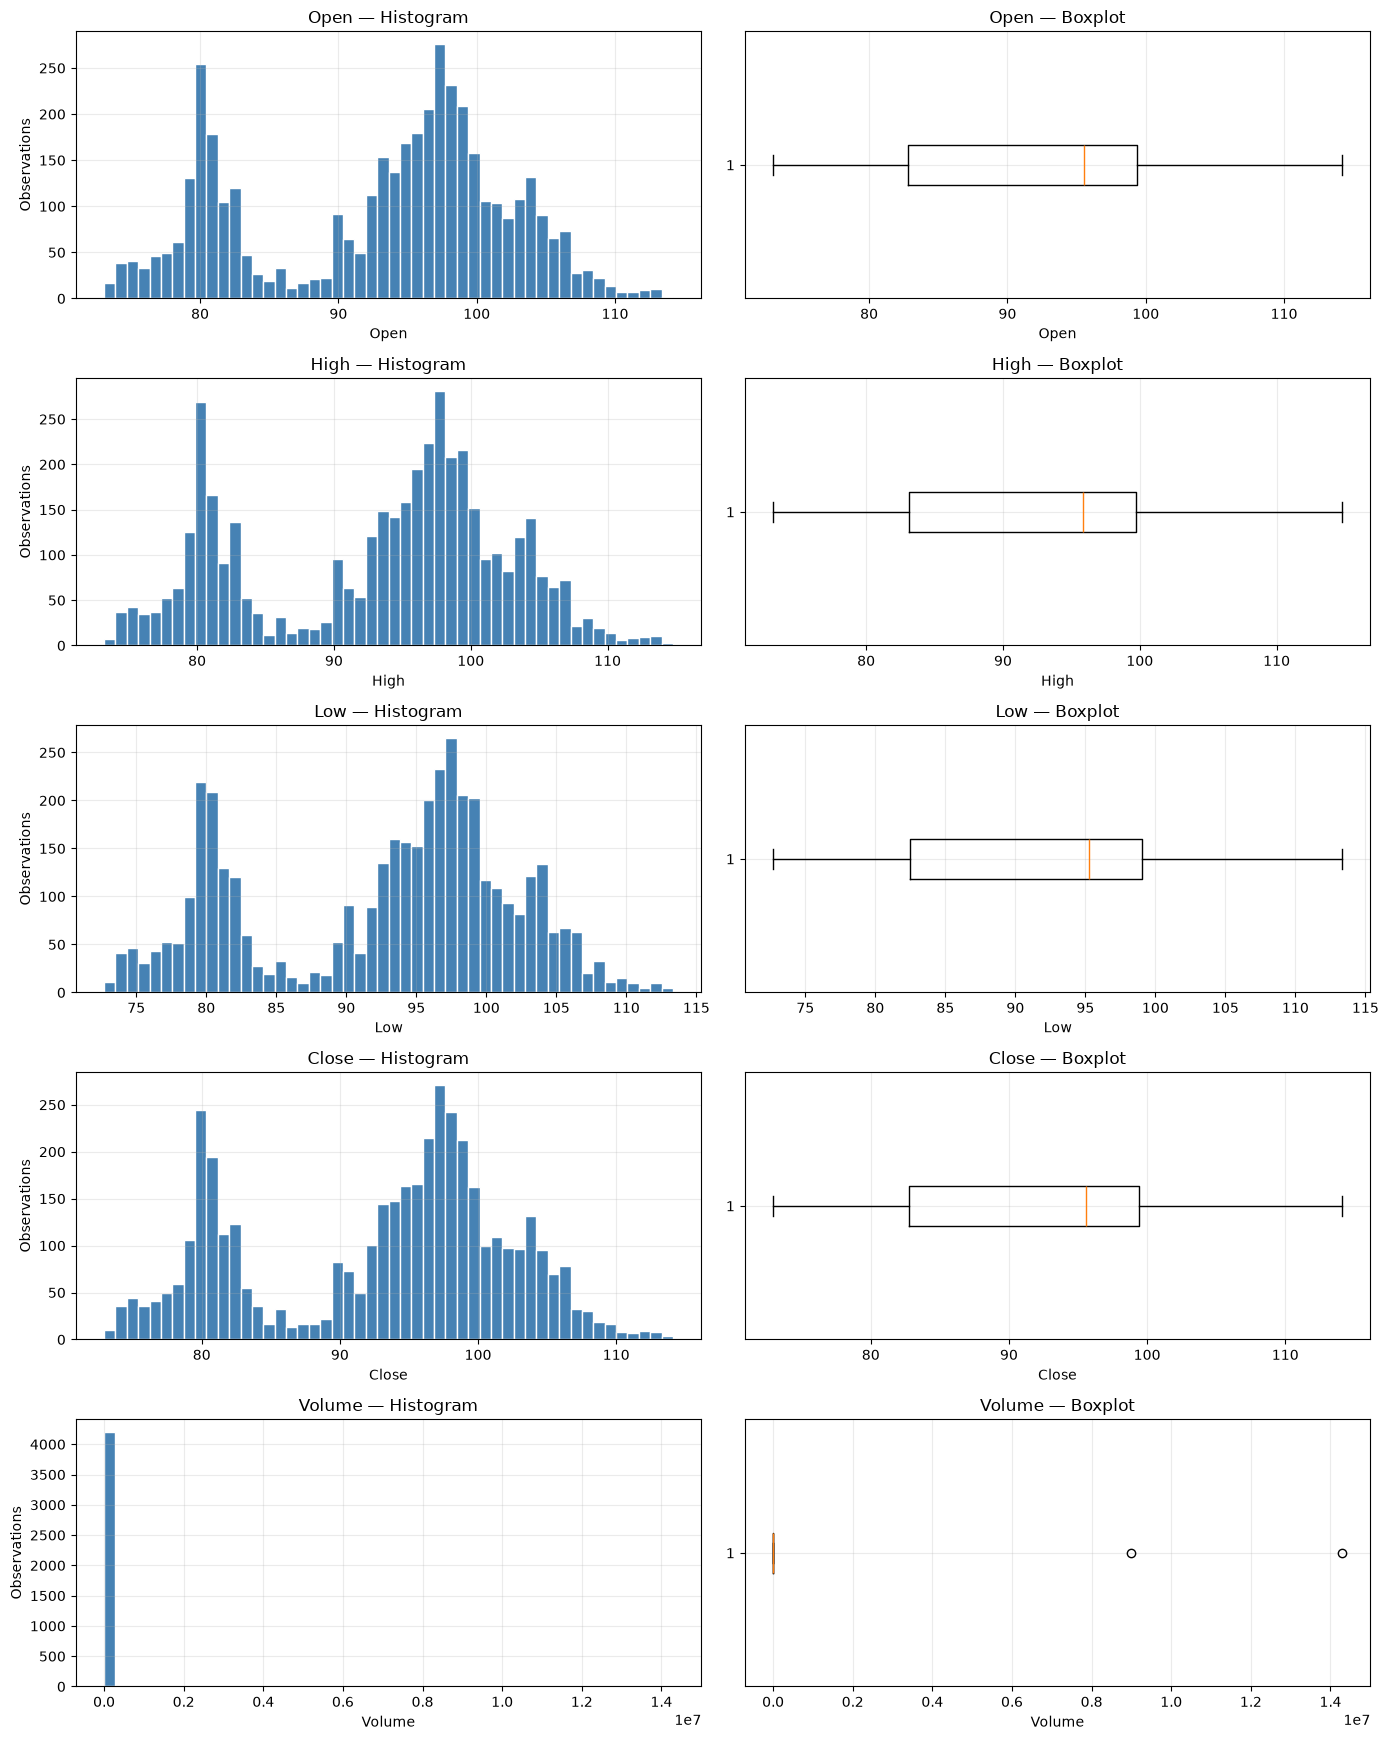

In [9]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 2, figsize=(14, 3.5 * len(RAW_NUMERIC)), squeeze=False)
for row, column in enumerate(RAW_NUMERIC):
    values = raw_finite[column].dropna()
    if len(values):
        axes[row, 0].hist(values, bins=50, color='steelblue', edgecolor='white')
        axes[row, 1].boxplot(values, orientation='horizontal')
    axes[row, 0].set_title(column + ' — Histogram')
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel('Observations')
    axes[row, 1].set_title(column + ' — Boxplot')
    axes[row, 1].set_xlabel(column)
plt.tight_layout()
plt.show()

### 1.9 Diễn biến theo thời gian

Vẽ từng biến gốc riêng, giữ đơn vị riêng. Bảng theo năm hỗ trợ quan sát thay đổi quy mô. Một bước nhảy trên biểu đồ chỉ là candidate shock/structural break; cần xác minh trước khi gán nguyên nhân.


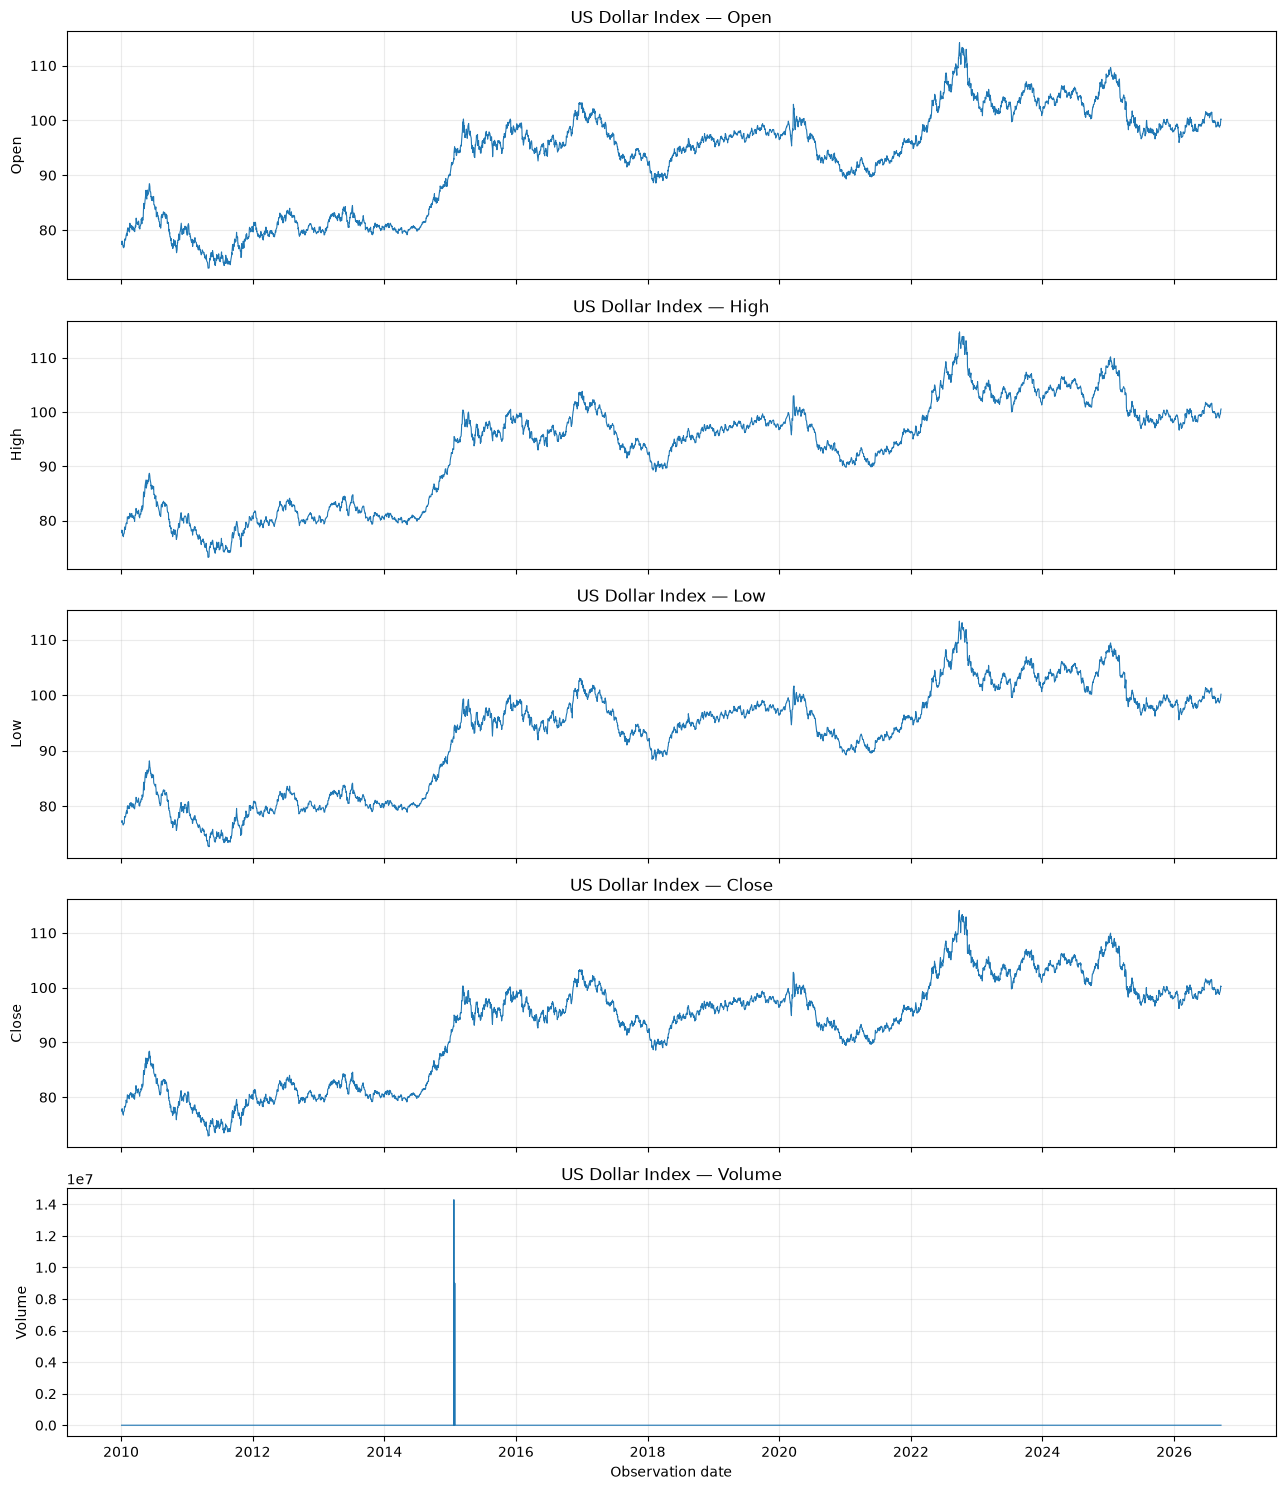


Thống kê các biến gốc theo năm


Open                                                            High  \
     count        mean      median       std         min         max count   
Date                                                                         
2010   252   81.204365   80.764999  2.856682   75.870003   88.449997   252   
2011   252   76.491270   76.299999  1.964321   73.059998   81.160004   252   
2012   250   80.570680   80.094997  1.394478   78.180000   83.980003   250   
2013   252   81.339048   81.274998  1.244969   79.099998   84.489998   252   
2014   252   82.546151   80.840000  3.184242   79.139999   90.190002   252   
2015   252   96.286309   96.274998  1.946185   90.360001  100.260002   252   
2016   251   96.836853   96.180000  2.399808   92.599998  103.260002   251   
2017   251   96.604861   96.070000  3.338755   91.489998  103.180000   251   
2018   251   93.546853   94.430000  2.634988   88.570000   97.599998   251   
2019   252   97.388810   97.450001  0.860208   95.160004   99.400002   252   
2020   253   95.817352   96.540001  3.144294   89.610001  102.940002   253   
2021   252   92.487619   92.355000  1.915234   89.320000   96.720001   252   
2022   251  104.017091  104.440002  5.247368   94.870003  114.190002   251   
2023   250  103.444560  103.314999  1.621723   99.750000  107.059998   250   
2024   252  104.167103  104.215000  1.760706  100.279999  108.480003   252   
2025   252  100.811190   99.225002  3.682251   96.620003  109.639999   252   
2026   179   99.216536   99.139999  1.191168   95.970001  101.599998   179   

                                        ...       Close                        \
            mean      median       std  ...      median       std         min   
Date                                    ...                                     
2010   81.566389   81.095001  2.877952  ...   80.720001  2.843392   75.879997   
2011   76.859683   76.640003  1.981438  ...   76.239998  1.967022   72.930000   
2012   80.889960   80.340000  1.400863  ...   80.070000  1.397877   78.269997   
2013   81.725913   81.630001  1.324854  ...   81.355000  1.283181   79.129997   
2014   82.758810   81.035000  3.258904  ...   80.825001  3.222005   79.139999   
2015   96.711905   96.605000  1.922995  ...   96.285000  1.926453   91.080002   
2016   97.185339   96.519997  2.437583  ...   96.139999  2.431039   92.629997   
2017   96.868048   96.239998  3.361892  ...   96.050003  3.331188   91.330002   
2018   93.851315   94.730003  2.623328  ...   94.489998  2.642426   88.589996   
2019   97.596309   97.639999  0.848297  ...   97.470001  0.855384   95.220001   
2020   96.116798   96.809998  3.195237  ...   96.459999  3.171532   89.629997   
2021   92.730992   92.584999  1.910476  ...   92.349998  1.917951   89.440002   
2022  104.486096  104.930000  5.355127  ...  104.510002  5.229213   94.790001   
2023  103.779560  103.615002  1.612937  ...  103.339996  1.628281   99.769997   
2024  104.455754  104.454998  1.761683  ...  104.255001  1.767989  100.370003   
2025  101.115992   99.495003  3.702079  ...   99.230000  3.667236   96.629997   
2026   99.480838   99.440002  1.159590  ...   99.190002  1.189392   96.220001   

                 Volume                                                   
             max  count          mean median           std min       max  
Date                                                                      
2010   88.400002    252      0.000000    0.0  0.000000e+00   0         0  
2011   81.010002    252      0.000000    0.0  0.000000e+00   0         0  
2012   84.010002    250      0.000000    0.0  0.000000e+00   0         0  
2013   84.580002    252      0.000000    0.0  0.000000e+00   0         0  
2014   90.269997    252      0.000000    0.0  0.000000e+00   0         0  
2015  100.330002    252  92420.634921    0.0  1.061930e+06   0  14290000  
2016  103.290001    251      0.000000    0.0  0.000000e+00   0         0  
2017  103.209999    251      0.000000    0.0  0.000000e+00   0         0  

In [10]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 1, figsize=(13, 3 * len(RAW_NUMERIC)), squeeze=False, sharex=True)
for row, column in enumerate(RAW_NUMERIC):
    axes[row, 0].plot(df['Date'], raw_finite[column], linewidth=.8)
    axes[row, 0].set_title(TITLE + ' — ' + column)
    axes[row, 0].set_ylabel(column)
axes[-1, 0].set_xlabel('Observation date')
plt.tight_layout()
plt.show()

annual_raw = raw_finite.groupby(df['Date'].dt.year).agg(['count','mean','median','std','min','max'])
print('\nThống kê các biến gốc theo năm')
display(annual_raw)

**Điểm cần chú ý riêng:** kiểm tra tỷ lệ Volume = 0 và các giá trị khác 0. Không tự hiểu 0 là missing hoặc tự fill Volume.


## Part 2 — Feature-oriented EDA

Phân tích từng feature của **Dollar Index** theo thứ tự: câu hỏi → đại lượng cần đo → cách tính → bảng/biểu đồ.

Cấu hình EDA: lag **1/2/3/5 phiên**, volatility **5/20/60 phiên**, MA **5/20/50 phiên**.

Các feature được tạo trên bản sao `dollar_index`, còn `df` giữ các biến gốc. Return và volatility lưu ở dạng tỷ lệ (0.01 = 1%), hiển thị theo %. Lag và cửa sổ tính theo phiên quan sát của chính nguồn.


### 2.0 Chuẩn bị dữ liệu và cấu hình

Giữ `df` của Part 1 nguyên vẹn, tạo bản sao `dollar_index`. Kiểm tra điều kiện tính feature bằng thông báo. Nếu Date/Close chưa hợp lệ, các cell tính toán sẽ in lý do bỏ qua thay vì tạo kết quả không đáng tin. OHLC cần kiểm tra riêng ở mục Intraday Range.


In [11]:

dollar_index = df.copy()


LAGS = [1, 2, 3, 5]
VOL_WINDOWS = [5, 20, 60]
MA_WINDOWS = [5, 20, 50]


feature_ready = True
if dollar_index.empty:
    print('Cảnh báo: Dữ liệu rỗng; chưa tính feature.')
    feature_ready = False
if dollar_index['Date'].isna().any() or dollar_index['Date'].duplicated().any():
    print('Cảnh báo: Date thiếu hoặc trùng; cần kiểm tra lại Part 1.')
    feature_ready = False
if not dollar_index['Date'].is_monotonic_increasing:
    print('Cảnh báo: Date chưa tăng dần; cần kiểm tra thứ tự ở Part 1.')
    feature_ready = False
invalid_close = dollar_index['Close'].isna() | dollar_index['Close'].isin([float('inf'), -float('inf')]) | (dollar_index['Close'] <= 0)
if invalid_close.any():
    print(f'Cảnh báo: Có {int(invalid_close.sum())} Close thiếu, không hữu hạn hoặc không dương.')
    feature_ready = False
if feature_ready:
    print(f'Dữ liệu đủ điều kiện tính feature trên {len(dollar_index):,} phiên quan sát.')
    print('Các dòng warm-up sẽ để NaN, không fill bằng 0.')
else:
    print('Các cell feature bên dưới sẽ bỏ qua phép tính cho tới khi đầu vào được xử lý.')


feature_columns = []

Dữ liệu đủ điều kiện tính feature trên 4,204 phiên quan sát.
Các dòng warm-up sẽ để NaN, không fill bằng 0.


### 2.1 Daily Return

**Câu hỏi:** Giá Dollar Index hôm nay thay đổi bao nhiêu so với phiên quan sát trước?

**Ý nghĩa:** Đo biến động tương đối để giảm ảnh hưởng của mặt bằng giá dài hạn.

**Cách tính và đơn vị:** `Daily_Return(t) = Close(t) / Close(t−1) − 1`. Dòng đầu thiếu vì chưa có phiên trước. Không forward-fill.

**Thống kê và biểu đồ:** Bảng thống kê theo %, line chart, histogram/boxplot và 10 phiên có |return| lớn nhất. Các phiên cực trị chỉ được đánh dấu để rà soát, không bị xóa.



Thống kê Daily Return — đơn vị % mỗi phiên


,Return (%)
count,4203.000000
mean,0.007090
std,0.443266
min,-2.370232
1%,-1.106441
25%,-0.249676
50%,0.009942
75%,0.259677
99%,1.166033
max,2.052815


Số dòng thiếu do chưa có phiên trước: 1

10 phiên có độ lớn Daily Return cao nhất


,Date,Close,Return (%)
152,2010-08-11,82.290001,1.844057
365,2011-06-15,75.599998,1.708592
459,2011-10-27,74.870003,-1.745399
1490,2015-12-03,97.620003,-2.370232
1631,2016-06-24,95.449997,2.052815
3232,2022-11-04,110.879997,-1.815287
3236,2022-11-10,108.209999,-2.116693
3237,2022-11-11,106.290001,-1.774326
3836,2025-04-03,102.070000,-1.676137
3841,2025-04-10,100.870003,-1.972788


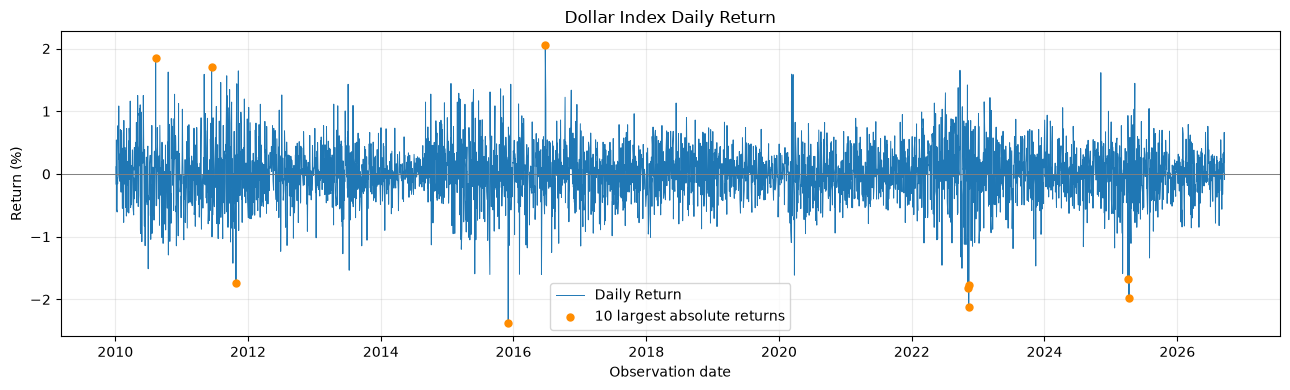

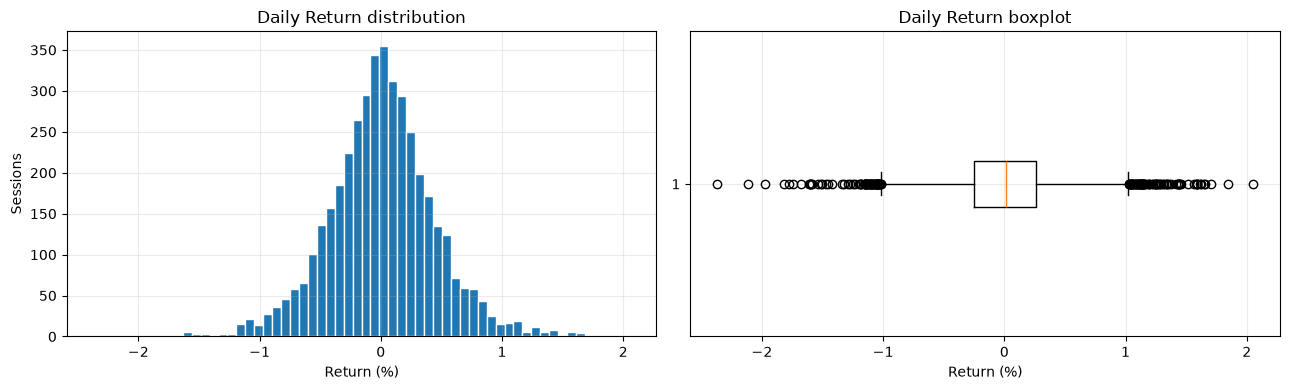

In [12]:
if feature_ready:
    
    dollar_index['Daily_Return'] = dollar_index['Close'].pct_change(fill_method=None)
    feature_columns.append('Daily_Return')
    return_percent = dollar_index['Daily_Return'] * 100

    print('\nThống kê Daily Return — đơn vị % mỗi phiên')
    display(return_percent.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame('Return (%)'))
    print('Số dòng thiếu do chưa có phiên trước:', int(dollar_index['Daily_Return'].isna().sum()))

    
    extreme_rows = dollar_index['Daily_Return'].abs().nlargest(10).index
    extreme_table = dollar_index.loc[extreme_rows, ['Date', 'Close']].copy()
    extreme_table['Return (%)'] = return_percent.loc[extreme_rows]
    print('\n10 phiên có độ lớn Daily Return cao nhất')
    display(extreme_table.sort_values('Date'))

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(dollar_index['Date'], return_percent, linewidth=.7, label='Daily Return')
    ax.scatter(dollar_index.loc[extreme_rows, 'Date'], return_percent.loc[extreme_rows],
               color='darkorange', s=25, label='10 largest absolute returns', zorder=3)
    ax.axhline(0, color='gray', linewidth=.7)
    ax.set(title='Dollar Index Daily Return', xlabel='Observation date', ylabel='Return (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(return_percent.dropna(), bins=60, edgecolor='white')
    axes[0].set(title='Daily Return distribution', xlabel='Return (%)', ylabel='Sessions')
    axes[1].boxplot(return_percent.dropna(), orientation='horizontal')
    axes[1].set(title='Daily Return boxplot', xlabel='Return (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Daily Return: kiểm tra thông báo ở mục 2.0.')

### 2.2 Lagged Return

**Câu hỏi:** Biến động các phiên trước có đi cùng quán tính hoặc đảo chiều trong chính Dollar Index không?

**Ý nghĩa:** Đặt giả thuyết momentum/reversal từ lịch sử, chưa kiểm tra khả năng dự báo Gold t+1.

**Cách tính và đơn vị:** `Return_Lag_k(t) = Daily_Return(t−k)` bằng `shift(k)`, k = 1,2,3,5 phiên. Đây không phải số ngày lịch.

**Thống kê và biểu đồ:** Bảng mapping ngày hiện tại/ngày nguồn, số cặp hợp lệ, correlation nội chuỗi và scatter từng lag với return hiện tại.



Lag 1 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,2010-01-04,NaN
2,2010-01-06,2010-01-05,0.116089
3,2010-01-07,2010-01-06,-0.167489
4,2010-01-08,2010-01-07,0.542013
5,2010-01-11,2010-01-08,-0.564757
6,2010-01-12,2010-01-11,-0.606688
7,2010-01-13,2010-01-12,-0.064939



Lag 2 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,2010-01-04,NaN
3,2010-01-07,2010-01-05,0.116089
4,2010-01-08,2010-01-06,-0.167489
5,2010-01-11,2010-01-07,0.542013
6,2010-01-12,2010-01-08,-0.564757
7,2010-01-13,2010-01-11,-0.606688



Lag 3 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,2010-01-04,NaN
4,2010-01-08,2010-01-05,0.116089
5,2010-01-11,2010-01-06,-0.167489
6,2010-01-12,2010-01-07,0.542013
7,2010-01-13,2010-01-08,-0.564757



Lag 5 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,NaT,NaN
4,2010-01-08,NaT,NaN
5,2010-01-11,2010-01-04,NaN
6,2010-01-12,2010-01-05,0.116089
7,2010-01-13,2010-01-06,-0.167489


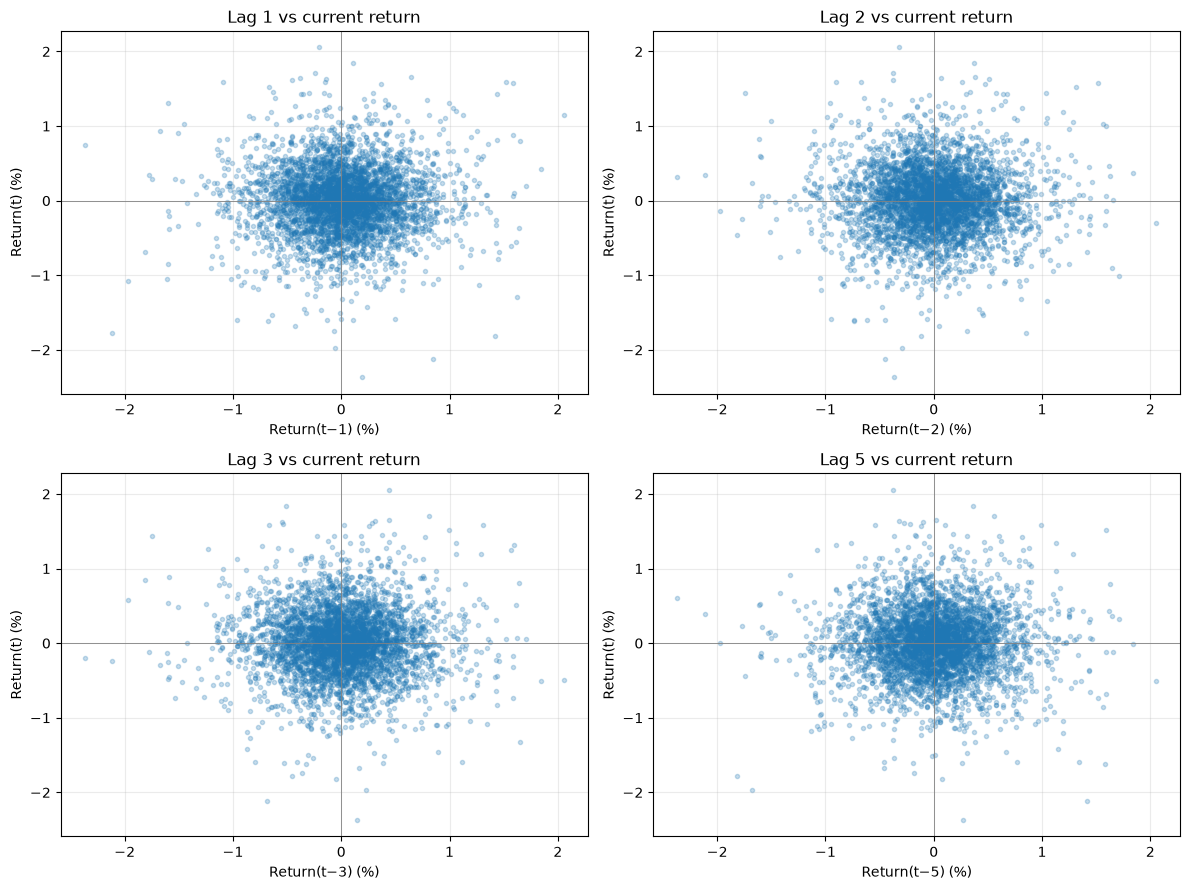


Tóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag


,Lag (sessions),Valid pairs,Missing lag values,Correlation with current return
0,1,4202,2,0.013141
1,2,4201,3,-0.007965
2,3,4200,4,-0.014530
3,5,4198,6,0.001558


In [13]:
if feature_ready:
    lag_summary = []
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for lag, ax in zip(LAGS, axes.flat):
        
        column = f'Return_Lag_{lag}'
        dollar_index[column] = dollar_index['Daily_Return'].shift(lag)
        feature_columns.append(column)

        
        mapping = dollar_index[['Date']].copy()
        mapping['Source_date'] = dollar_index['Date'].shift(lag)
        mapping['Lagged Return (%)'] = dollar_index[column] * 100
        print(f'\nLag {lag} phiên — 8 dòng đầu của mapping ngày nguồn')
        display(mapping.head(8))

        
        pair = dollar_index[[column, 'Daily_Return']].dropna()
        lag_summary.append({'Lag (sessions)': lag, 'Valid pairs': len(pair),
                            'Missing lag values': int(dollar_index[column].isna().sum()),
                            'Correlation with current return': pair[column].corr(pair['Daily_Return'])})
        ax.scatter(pair[column] * 100, pair['Daily_Return'] * 100, s=9, alpha=.25)
        ax.axhline(0, color='gray', linewidth=.6)
        ax.axvline(0, color='gray', linewidth=.6)
        ax.set(title=f'Lag {lag} vs current return', xlabel=f'Return(t−{lag}) (%)', ylabel='Return(t) (%)')
    plt.tight_layout()
    plt.show()
    print('\nTóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag')
    display(pd.DataFrame(lag_summary))
else:
    print('Chưa tính Lagged Return: kiểm tra mục 2.0.')

### 2.3 Rolling Volatility

**Câu hỏi:** Thị trường gần đây đang yên bình hay biến động mạnh?

**Ý nghĩa:** Mô tả trạng thái rủi ro/biến động của Dollar Index qua các horizon khác nhau.

**Cách tính và đơn vị:** Độ lệch chuẩn mẫu (`ddof=1`) của Daily_Return trong 5/20/60 phiên gần nhất, gồm t. `min_periods=window`; không annualize.

**Thống kê và biểu đồ:** Biểu đồ ba đường volatility, thống kê và số dòng warm-up, boxplot để so độ phân tán.



Rolling Volatility — thống kê theo %, chưa annualize


,count,mean,std,min,25%,50%,75%,max
Volatility_5,4199.0,0.400212,0.190842,0.028877,0.267764,0.370190,0.493201,1.333649
Volatility_20,4184.0,0.421573,0.139819,0.129726,0.323751,0.395834,0.499691,1.049336
Volatility_60,4144.0,0.427370,0.120727,0.170527,0.340122,0.402286,0.507309,0.823310


Volatility_5: 5 dòng thiếu do warm-up.
Volatility_20: 20 dòng thiếu do warm-up.
Volatility_60: 60 dòng thiếu do warm-up.


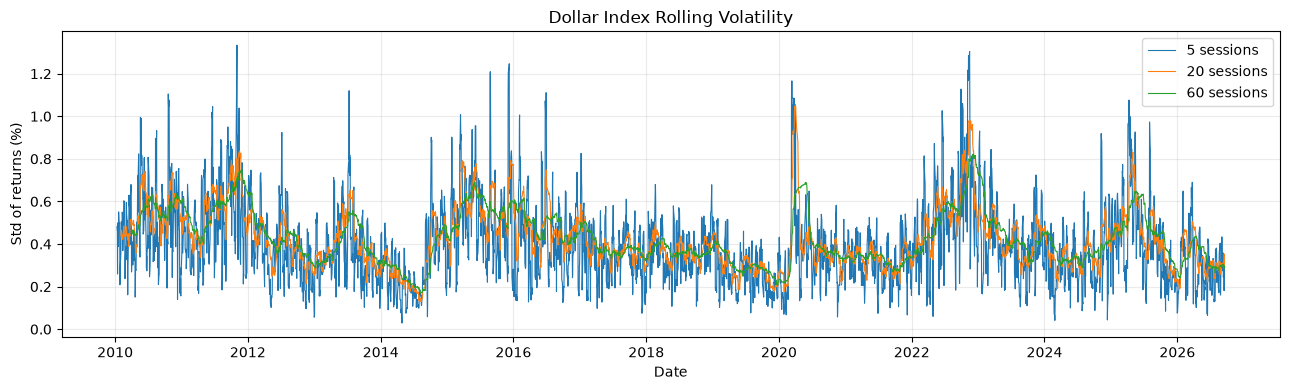

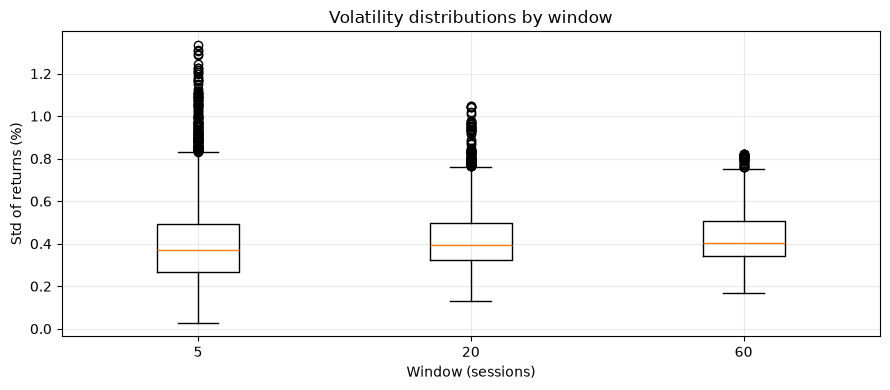

In [14]:
if feature_ready:
    volatility_names = []
    for window in VOL_WINDOWS:
        
        column = f'Volatility_{window}'
        dollar_index[column] = dollar_index['Daily_Return'].rolling(window=window, min_periods=window).std(ddof=1)
        volatility_names.append(column)
        feature_columns.append(column)

    print('\nRolling Volatility — thống kê theo %, chưa annualize')
    display((dollar_index[volatility_names] * 100).describe().T)
    for column in volatility_names:
        print(f'{column}: {int(dollar_index[column].isna().sum())} dòng thiếu do warm-up.')

    fig, ax = plt.subplots(figsize=(13, 4))
    for window, column in zip(VOL_WINDOWS, volatility_names):
        ax.plot(dollar_index['Date'], dollar_index[column] * 100, linewidth=.8, label=f'{window} sessions')
    ax.set(title='Dollar Index Rolling Volatility', xlabel='Date', ylabel='Std of returns (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    box_values = [(dollar_index[column].dropna() * 100).tolist() for column in volatility_names]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(box_values, tick_labels=[str(w) for w in VOL_WINDOWS])
    ax.set(title='Volatility distributions by window', xlabel='Window (sessions)', ylabel='Std of returns (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Rolling Volatility: kiểm tra mục 2.0.')

### 2.4 Moving Average / Distance to MA

**Câu hỏi:** Giá hiện tại cao hay thấp so với mặt bằng gần đây?

**Ý nghĩa:** MA mô tả trend; khoảng cách tương đối giúp so sánh các thời kỳ có mức giá khác nhau.

**Cách tính và đơn vị:** `MA_w = rolling mean(Close, w)` với w = 5/20/50; `Distance_to_MA_w = Close/MA_w−1`. MA dùng index points, distance dùng tỷ lệ.

**Thống kê và biểu đồ:** Close và MA toàn kỳ, góc nhìn 120 phiên cuối để dễ phân biệt các đường, distance theo thời gian và thống kê theo %. 120 phiên chỉ là phạm vi hiển thị.


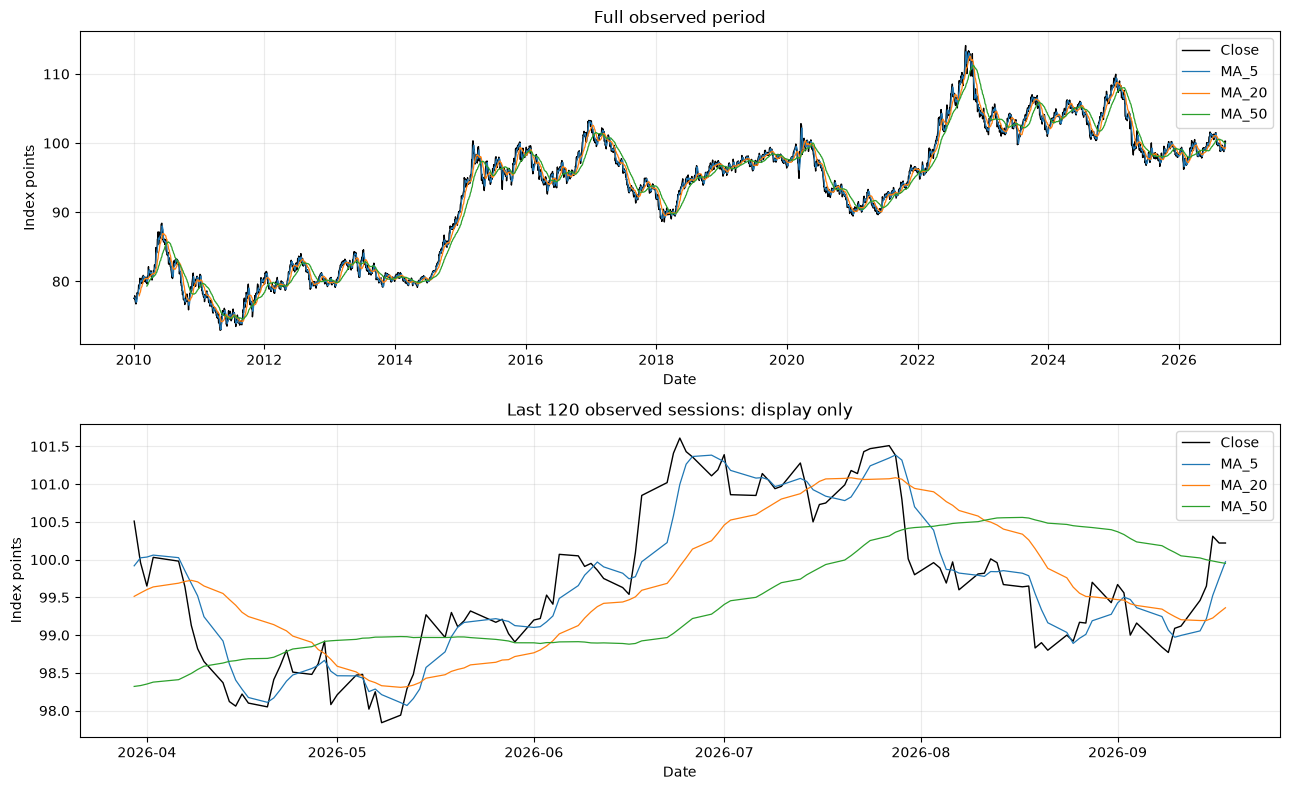

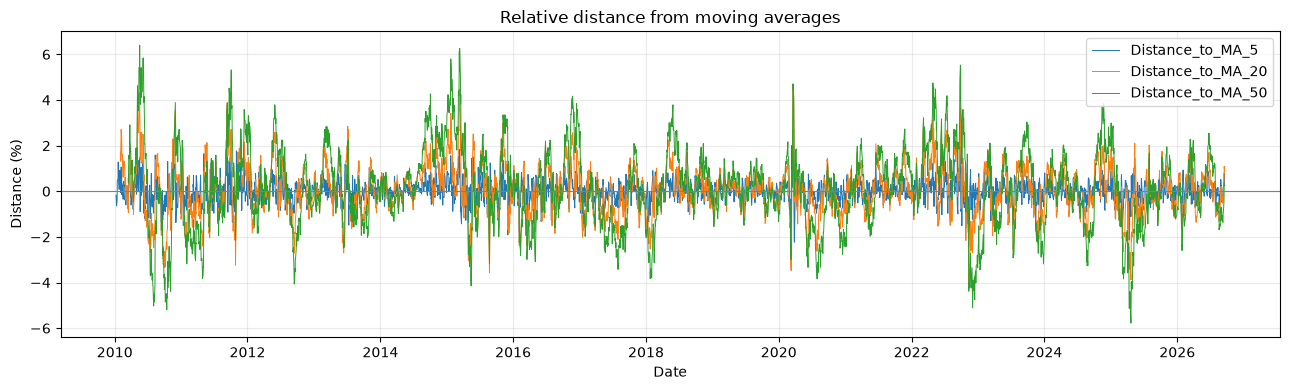


Distance to MA — thống kê theo %


,count,mean,std,min,25%,50%,75%,max
Distance_to_MA_5,4200.0,0.012504,0.487616,-2.448651,-0.279086,0.012531,0.304417,2.690172
Distance_to_MA_20,4185.0,0.057576,1.076641,-4.195772,-0.615672,0.053779,0.722057,4.678763
Distance_to_MA_50,4155.0,0.137022,1.746255,-5.776330,-0.952298,0.135809,1.216351,6.399606



MA — thống kê theo index points


,count,mean,std,min,25%,50%,75%,max
MA_5,4200.0,93.014999,9.256047,73.0340,82.7790,95.593001,99.3705,113.2500
MA_20,4185.0,93.031370,9.223041,74.1570,82.7425,95.580000,99.3085,112.5850
MA_50,4155.0,93.056861,9.166536,74.5384,82.6795,95.731801,99.0876,111.2402


In [15]:
if feature_ready:
    ma_names = []
    distance_names = []
    for window in MA_WINDOWS:
        
        ma_column = f'MA_{window}'
        distance_column = f'Distance_to_MA_{window}'
        dollar_index[ma_column] = dollar_index['Close'].rolling(window=window, min_periods=window).mean()
        dollar_index[distance_column] = dollar_index['Close'] / dollar_index[ma_column] - 1
        ma_names.append(ma_column)
        distance_names.append(distance_column)
        feature_columns.extend([ma_column, distance_column])

    
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))
    for ax, view, label in [(axes[0], dollar_index, 'Full observed period'),
                            (axes[1], dollar_index.tail(120), 'Last 120 observed sessions: display only')]:
        ax.plot(view['Date'], view['Close'], color='black', linewidth=1, label='Close')
        for column in ma_names:
            ax.plot(view['Date'], view[column], linewidth=.9, label=column)
        ax.set(title=label, xlabel='Date', ylabel='Index points')
        ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(13, 4))
    for column in distance_names:
        ax.plot(dollar_index['Date'], dollar_index[column] * 100, linewidth=.7, label=column)
    ax.axhline(0, color='gray', linewidth=.8)
    ax.set(title='Relative distance from moving averages', xlabel='Date', ylabel='Distance (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    print('\nDistance to MA — thống kê theo %')
    display((dollar_index[distance_names] * 100).describe().T)
    print('\nMA — thống kê theo index points')
    display(dollar_index[ma_names].describe().T)
else:
    print('Chưa tính MA và Distance to MA: kiểm tra mục 2.0.')